# Telco customer churn: validation set and decision threshold

Same raw data, 20% test set and random seed as [03-modeling](03-modeling.ipynb). A validation set is carved out of the original training set, numeric features are standardised, and the decision threshold is searched on the validation set. The original test set has been looked at once in notebook 03; from here on it is not used to choose anything.

## 1. Reproducing the train/test split

The notebook starts from the raw CSV and does not depend on variables from another notebook.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
y = df["Churn"]
x = df.drop(columns=["Churn", "customerID"])

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=2002,
    stratify=y,
)

print("Original training set:", len(x_train))
print("Original test set:", len(x_test))

Original training set: 5634
Original test set: 1409


## 2. Carving a validation set out of the training set

`train_test_split` is called a second time on `x_train, y_train` only: 20% for validation, same seed, stratified on `y_train`. Expected sizes: 4,507 for fitting and 1,127 for validation, with the test set still at 1,409. The two index sets must not overlap.

In [2]:
x_fit, x_val, y_fit, y_val = train_test_split(
    x_train, y_train,
    test_size=0.2,
    random_state=2002,
    stratify=y_train,
)

print("Fitting subset:", len(x_fit))
print("Validation set:", len(x_val))
print("Original test set:", len(x_test))

print("Customers in both fitting and validation:", not x_fit.index.intersection(x_val.index).empty)
print("Features and target aligned:",
      x_fit.index.equals(y_fit.index),
      x_val.index.equals(y_val.index))

print("Churn share, fitting subset:", y_fit.value_counts(normalize=True).round(4).to_dict())
print("Churn share, validation set:", y_val.value_counts(normalize=True).round(4).to_dict())

Fitting subset: 4507
Validation set: 1127
Original test set: 1409
Customers in both fitting and validation: False
Features and target aligned: True True
Churn share, fitting subset: {'No': 0.7346, 'Yes': 0.2654}
Churn share, validation set: {'No': 0.7347, 'Yes': 0.2653}


## 3. Preprocessing learned from the fitting subset

Numeric columns: median imputation, then standardisation. Categorical columns: one-hot encoding. Every statistic is learned from `x_fit` only.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

x_fit = x_fit.copy()
x_val = x_val.copy()

# TotalCharges is text in the raw CSV; blanks become NaN
x_fit["TotalCharges"] = pd.to_numeric(x_fit["TotalCharges"], errors="coerce")
x_val["TotalCharges"] = pd.to_numeric(x_val["TotalCharges"], errors="coerce")

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
val_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

val_numeric_pipeline.fit(x_fit[numeric_features])

fit_numeric = val_numeric_pipeline.transform(x_fit[numeric_features])
val_numeric = val_numeric_pipeline.transform(x_val[numeric_features])

print("Medians learned from the fitting subset:",
      val_numeric_pipeline.named_steps["imputer"].statistics_)
print("Missing after preprocessing:",
      pd.isna(fit_numeric).sum(),
      pd.isna(val_numeric).sum())

Medians learned from the fitting subset: [  28.     70.4  1374.35]
Missing after preprocessing: 0 0


In [4]:
from sklearn.preprocessing import OneHotEncoder

# SeniorCitizen is stored as 0/1 but is a category
categorical_features = ["SeniorCitizen"] + x_fit.select_dtypes(
    exclude="number"
).columns.tolist()

val_cat_encoder = OneHotEncoder(handle_unknown="ignore")
val_cat_encoder.fit(x_fit[categorical_features])

fit_cat = val_cat_encoder.transform(x_fit[categorical_features])
val_cat = val_cat_encoder.transform(x_val[categorical_features])

print("Categorical columns:", categorical_features)
print("Fitting subset, encoded:", fit_cat.shape)
print("Validation set, encoded:", val_cat.shape)

Categorical columns: ['SeniorCitizen', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Fitting subset, encoded: (4507, 43)
Validation set, encoded: (1127, 43)


In [5]:
from scipy.sparse import hstack

X_fit_ready = hstack([fit_numeric, fit_cat]).tocsr()
X_val_ready = hstack([val_numeric, val_cat]).tocsr()

print("Fitting subset:", X_fit_ready.shape)
print("Validation set:", X_val_ready.shape)
print("Targets:", len(y_fit), len(y_val))

Fitting subset: (4507, 46)
Validation set: (1127, 46)
Targets: 4507 1127


## 4. Model and validation results at the default threshold

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

val_model = LogisticRegression(max_iter=2800)
val_model.fit(X_fit_ready, y_fit)

val_pred = val_model.predict(X_val_ready)

print(classification_report(y_val, val_pred))

cm = confusion_matrix(y_val, val_pred, labels=["No", "Yes"])
display(pd.DataFrame(
    cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"],
))

              precision    recall  f1-score   support

          No       0.85      0.92      0.89       828
         Yes       0.73      0.56      0.63       299

    accuracy                           0.83      1127
   macro avg       0.79      0.74      0.76      1127
weighted avg       0.82      0.83      0.82      1127



,Predicted No,Predicted Yes
Actual No,765,63
Actual Yes,131,168


In [7]:
print("Iterations used:", val_model.n_iter_)
print("Classes behind the probability columns:", val_model.classes_)

# Locate the Yes column by class name instead of assuming a position
yes_col = list(val_model.classes_).index("Yes")
val_yes_prob = val_model.predict_proba(X_val_ready)[:, yes_col]

print("Churn probability of the first 5 customers:", val_yes_prob[:5])

Iterations used: [22]
Classes behind the probability columns: ['No' 'Yes']
Churn probability of the first 5 customers: [0.53601584 0.01343822 0.00185616 0.01010683 0.25934543]


## 5. Three thresholds compared

In [8]:
import numpy as np

pred_05 = np.where(val_yes_prob >= 0.5, "Yes", "No")
print("Threshold 0.5 reproduces model.predict:",
      (pred_05 == val_pred).all())

for threshold in [0.5, 0.4, 0.3]:
    predicted = np.where(val_yes_prob >= threshold, "Yes", "No")
    print(threshold, "predicted churners:", (predicted == "Yes").sum())

Threshold 0.5 reproduces model.predict: True
0.5 predicted churners: 231
0.4 predicted churners: 309
0.3 predicted churners: 407


In [9]:
rows = []

for threshold in [0.5, 0.4, 0.3]:
    predicted = np.where(val_yes_prob >= threshold, "Yes", "No")

    tn, fp, fn, tp = confusion_matrix(
        y_val, predicted, labels=["No", "Yes"]
    ).ravel()

    rows.append({
        "threshold": threshold,
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
    })

comparison = pd.DataFrame(rows)

tp = comparison["TP"]
fp = comparison["FP"]
fn = comparison["FN"]

comparison["precision"] = (tp / (tp + fp)).round(2)
comparison["recall"] = (tp / (tp + fn)).round(2)
comparison["F1"] = (2 * tp / (2 * tp + fp + fn)).round(2)

display(comparison)

,threshold,TP,FN,FP,TN,precision,recall,F1
0,0.5,168,131,63,765,0.73,0.56,0.63
1,0.4,204,95,105,723,0.66,0.68,0.67
2,0.3,232,67,175,653,0.57,0.78,0.66


In [10]:
pred_04 = np.where(val_yes_prob >= 0.4, "Yes", "No")

# Customers whose prediction flips from No to Yes when the threshold drops from 0.5 to 0.4
changed = (pred_05 == "No") & (pred_04 == "Yes")

changed_cases = pd.DataFrame({
    "churn_probability": val_yes_prob[changed],
    "actual": y_val.to_numpy()[changed],
})

print("Predictions that changed:", len(changed_cases))
print(changed_cases["actual"].value_counts().to_dict())
display(changed_cases.head())

Predictions that changed: 78
{'No': 42, 'Yes': 36}


,churn_probability,actual
0,0.438092,Yes
1,0.414890,No
2,0.468012,Yes
3,0.404516,No
4,0.469215,Yes


On the same validation set, the churn-class F1 at thresholds 0.5, 0.4 and 0.3 is **0.63, 0.67 and 0.66**. Of the three, 0.4 is highest; whether to use it depends on the relative cost of a missed churner and a false alarm.

At 0.5 the confusion matrix is TN 765, FP 63, FN 131, TP 168; at 0.4 it is TN 723, FP 105, FN 95, TP 204. Lowering the threshold from 0.5 to 0.4 finds **36** more churners and adds **42** false alarms.

With standardised numeric features the solver converges in **22** iterations. Fewer iterations does not mean better predictions. The search below continues on the same validation probabilities; the test set takes no part in it.

## 6. Fine-grained threshold search

In [11]:
max_f1 = -1
best_threshold = None
rows = []

for step in range(1, 1000):  # 0.001 to 0.999 in steps of 0.001
    threshold = step / 1000
    predicted = np.where(val_yes_prob >= threshold, "Yes", "No")

    tn, fp, fn, tp = confusion_matrix(
        y_val, predicted, labels=["No", "Yes"]
    ).ravel()

    f1 = 2 * tp / (2 * tp + fp + fn)

    if f1 > max_f1:
        max_f1 = f1
        best_threshold = threshold

    rows.append({
        "threshold": threshold,
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "F1": f1,
    })

threshold_results = pd.DataFrame(rows)

print(f"Highest validation F1: {max_f1:.3f}")
print(f"At threshold: {best_threshold:.3f}")
display(threshold_results.sort_values("F1", ascending=False).head(10))

Highest validation F1: 0.674
At threshold: 0.409


,threshold,TP,FN,FP,TN,F1
408,0.409,202,97,98,730,0.674457
407,0.408,202,97,99,729,0.673333
406,0.407,202,97,99,729,0.673333
400,0.401,204,95,103,725,0.673267
401,0.402,204,95,103,725,0.673267
402,0.403,204,95,103,725,0.673267
409,0.410,201,98,98,730,0.672241
412,0.413,201,98,98,730,0.672241
411,0.412,201,98,98,730,0.672241
410,0.411,201,98,98,730,0.672241


Scanning 0.001 to 0.999 in steps of **0.001** on the validation set, the churn-class F1 is highest at **0.409**: F1 **0.674457**, with TP 202, FN 97, FP 98, TN 730. Compared with 0.5, that finds 34 more churners and adds 35 false alarms.

The F1 at 0.4 is about **0.671**, very close. 0.409 is only the best point for this model, this validation set and this grid. It is not a test score, and the grid is not refined further to chase differences in the third decimal on the same validation set.

## 7. Precision, recall and the F1 curve

Precision, recall and the number of predicted churners are added on a copy of the results. Ties at the maximum are listed, and the F1 curve is drawn around the candidates.

,threshold,TP,FN,FP,TN,F1,predicted_yes,precision,recall
408,0.409,202,97,98,730,0.674457,300,0.673333,0.675585


,threshold,predicted_yes,F1
408,0.409,300,0.674457


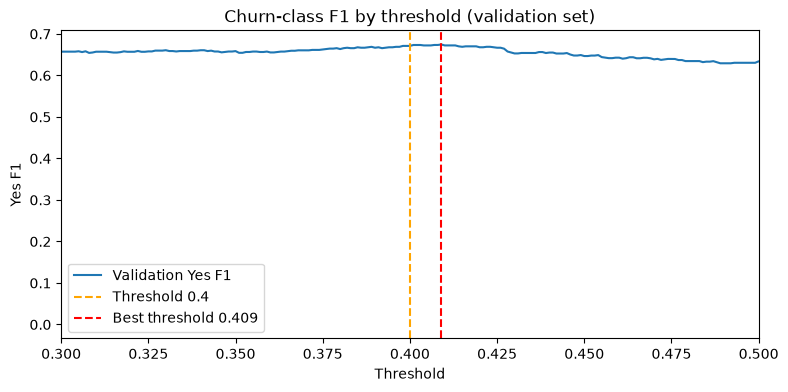

In [12]:
import matplotlib.pyplot as plt

results = threshold_results.copy()

results["predicted_yes"] = results["TP"] + results["FP"]

tp = results["TP"]
fp = results["FP"]
fn = results["FN"]

# A zero denominator gives NaN, shown as 0 here
results["precision"] = tp.div(tp + fp).fillna(0)
results["recall"] = tp.div(tp + fn).fillna(0)

display(results.loc[results["threshold"] == best_threshold])

ties = results.loc[
    results["F1"] == max_f1,
    ["threshold", "predicted_yes", "F1"]
]
display(ties)

plt.figure(figsize=(9, 4))
plt.plot(results["threshold"], results["F1"], label="Validation Yes F1")
plt.axvline(0.4, color="orange", linestyle="--", label="Threshold 0.4")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best threshold {best_threshold}")
plt.xlim(0.3, 0.5)
plt.title("Churn-class F1 by threshold (validation set)")
plt.xlabel("Threshold")
plt.ylabel("Yes F1")
plt.legend()
plt.show()

## 8. ROC-AUC

AUC is computed from the predicted probabilities with `Yes` as the positive class. It measures how well the model ranks customers and does not depend on the threshold: F1 changes between 0.5, 0.4 and 0.409, the AUC of these probabilities does not.

{0: 828, 1: 299}
Validation ROC-AUC: 0.8634316481669978


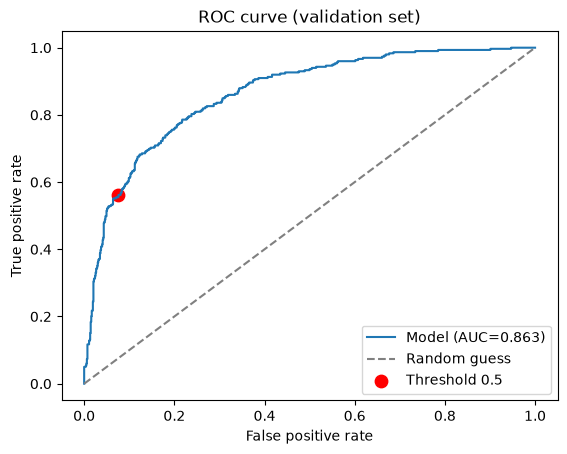

False positive rate at 0.5: 0.07608695652173914
True positive rate at 0.5: 0.5618729096989966
TP, FP: 168 63


In [13]:
from sklearn.metrics import roc_auc_score, roc_curve

y_val_binary = (y_val == "Yes").astype(int)
print(y_val_binary.value_counts().to_dict())

val_auc = roc_auc_score(y_val_binary, val_yes_prob)
print("Validation ROC-AUC:", val_auc)

fpr, tpr, roc_thresholds = roc_curve(y_val_binary, val_yes_prob)

# Position of the 0.5 threshold on the curve
tn, fp, fn, tp = confusion_matrix(
    y_val, np.where(val_yes_prob >= 0.5, "Yes", "No"), labels=["No", "Yes"]
).ravel()

plt.plot(fpr, tpr, label=f"Model (AUC={val_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.scatter(fp / (fp + tn), tp / (tp + fn), color="red", s=80, label="Threshold 0.5")
plt.title("ROC curve (validation set)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.show()

print("False positive rate at 0.5:", fp / (fp + tn))
print("True positive rate at 0.5:", tp / (tp + fn))
print("TP, FP:", tp, fp)

## 9. A capacity constraint, as an illustration

Suppose at most 250 of the 1,127 validation customers could be contacted. This cap is an illustration, not a confirmed business limit. Candidates with at most 250 predicted churners are kept and the one with the highest unrounded F1 is chosen; ties go to fewer predictions, then to the higher threshold. It is compared with the unconstrained candidate on TP, FP, FN and the number contacted. No business benefit is claimed.

In [14]:
eligible = results.loc[
    results["predicted_yes"] <= 250
].copy()

best_eligible = eligible.sort_values(
    ["F1", "predicted_yes", "threshold"],
    ascending=[False, True, False],
).head(1)

unrestricted = results.loc[results["threshold"] == best_threshold]

columns = ["plan", "threshold", "predicted_yes", "TP", "FP", "FN", "F1"]

comparison = pd.concat([
    unrestricted.assign(plan="No capacity limit"),
    best_eligible.assign(plan="At most 250 contacts"),
], ignore_index=True)

display(comparison[columns])
assert (best_eligible["predicted_yes"] <= 250).all()

,plan,threshold,predicted_yes,TP,FP,FN,F1
0,No capacity limit,0.409,300,202,98,97,0.674457
1,At most 250 contacts,0.469,250,176,74,123,0.641166


## Summary

- On the validation set the highest churn-class F1 is 0.6745 at threshold **0.409** (TP 202, FP 98, FN 97, TN 730; 300 customers flagged). Validation ROC-AUC is 0.8634.
- With a cap of 250 contacts the best candidate is 0.469 (TP 176, FP 74, FN 123; F1 0.6412): 50 fewer contacts, of which 26 are churners no longer found and 24 are false alarms avoided.
- Both numbers come from one validation set of 1,127 customers and are selection evidence, not an estimate of performance on new customers. The next notebook moves the same steps into a single scikit-learn Pipeline and adds cross-validation.